
**Gnasher Group — Dog Group Classification**

This project uses pretrained ImageNet EfficientNet-B0 predictions and breed-to-group mapping to suggest one of seven AKC dog groups. It preserves unsupported-dog and non-dog scores and returns “Uncertain” when the leading group score is below 50%. No new model was trained.  
**AI assistance:** ChatGPT helped generate starter code, the mapping module, and debugging guidance. I ran the notebook, tested photographs, recorded results, and answered the learning questions.

In [176]:
%pip install -q torch torchvision pillow matplotlib pandas

## 1. Load the model and its preprocessing

`weights` selects the pretrained parameters. `model.eval()` puts the network in prediction mode. `weights.transforms()` resizes, crops, and normalizes images exactly as these weights expect. We are reusing a trained model, not claiming we trained it.


In [177]:
import torch
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from PIL import Image
import matplotlib.pyplot as plt
import time

torch.set_num_threads(2)
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)
model.eval()
preprocess = weights.transforms()
labels = weights.meta['categories']
print('Loaded EfficientNet-B0 with', len(labels), 'ImageNet labels.')


Loaded EfficientNet-B0 with 1000 ImageNet labels.


## 2. Load a test photograph

Upload the photograph and gnasher_group_mapping.py to Colab’s /content folder. Set image_path to the uploaded photograph’s exact filename. The next cell stops with an error if that file is missing.  
This notebook currently displays the Border Collie example. The saved results table contains eight photographs tested during the same session. Earlier records remain in the exported CSV; a fresh runtime does not automatically restore them.

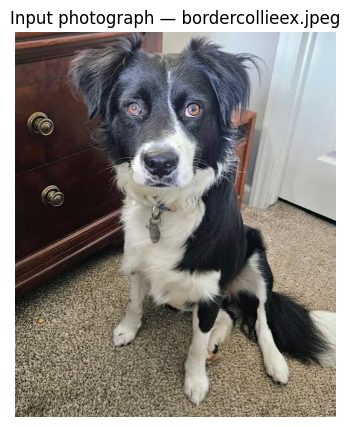

In [178]:
from pathlib import Path
from urllib.request import urlretrieve

image_path = Path('/content/bordercollieex.jpeg')
if not image_path.exists():
    raise FileNotFoundError(f"Upload this photo first: {image_path}")
image = Image.open(image_path).convert('RGB')
plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.axis('off')
plt.title(f"Input photograph — {image_path.name}")
plt.show()


## 3. Predict the top five labels

The preprocessing turns the image into a tensor. `unsqueeze(0)` adds a batch dimension because the model expects a batch of images. `torch.inference_mode()` avoids tracking gradients during prediction.

Softmax converts the 1,000 raw scores into relative probabilities that sum to one. These scores are **not calibrated guarantees** that a prediction is correct. `topk(5)` selects the five largest scores.


In [179]:

input_batch = preprocess(image).unsqueeze(0)
start = time.perf_counter()
with torch.inference_mode():
    probabilities = model(input_batch).softmax(dim=1)[0]
elapsed = time.perf_counter() - start
values, indices = probabilities.topk(5)

for score, index in zip(values.tolist(), indices.tolist()):
    print(f'{labels[index]:25s} {score:.1%}')
print(f'One forward pass on {next(model.parameters()).device}: {elapsed:.3f} seconds')
print('This is a first-call timing, not the final averaged speed benchmark.')


Border collie             76.8%
collie                    16.8%
Cardigan                  1.5%
kelpie                    0.2%
Appenzeller               0.2%
One forward pass on cpu: 0.167 seconds
This is a first-call timing, not the final averaged speed benchmark.


## Learning Reflection

1. What happened when you replaced the sample with your own dog photo? It predicted correctly. It did show some labels that were not correct as well though, like seatbelt.
2. Why do we need breed-to-group mapping before this becomes Gnasher Group? To help identify even with similar probabilities in breeds.
3. Why would a large softmax score alone not establish the model's accuracy?
It would cause overconfidence and wrong labeling and it could lead to bias.

## Sources
- [Official Torchvision EfficientNet-B0 API](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b0.html)
- [PyTorch Hub sample photograph](https://github.com/pytorch/hub/blob/master/images/dog.jpg)
- Professor's ITAI 1378 Technical Companion: first working demo with a pretrained classifier.


In [181]:
from gnasher_group_mapping import aggregate_group_scores

result = aggregate_group_scores(labels, probabilities.tolist())

for group, score in result["ranked_groups"]:
    print(f"{group:15s}: {score:.1%}")

print(f"Unsupported dog: {result['unsupported_dog']:.1%}")
print(f"Non-dog labels : {result['non_dog']:.1%}")

Herding        : 95.2%
Sporting       : 0.5%
Working        : 0.4%
Toy            : 0.3%
Terrier        : 0.1%
Non-Sporting   : 0.1%
Hound          : 0.1%
Unsupported dog: 0.5%
Non-dog labels : 2.8%


In [182]:
# Provisional threshold: test on more photos before final evaluation.
threshold = 0.50
top_group, top_score = result["ranked_groups"][0]

if top_score >= threshold:
    print(f"Suggested group: {top_group}")
    print(f"Group score: {top_score:.1%}")
else:
    print("Uncertain—no reliable group prediction.")
    print("Top two group candidates (not accepted classifications):")
    for group, score in result["ranked_groups"][:2]:
        print(f"  {group}: {score:.1%}")

Suggested group: Herding
Group score: 95.2%


In [183]:
import pandas as pd

# Keep previous records when this cell runs again.
if "test_records" not in globals():
    test_records = {}

# Set this from the photo's known breed BEFORE testing.
expected_group = "Herding"

top_group, top_score = result["ranked_groups"][0]
decision = top_group if top_score >= threshold else "Uncertain"

test_records[image_path.name] = {
    "Photo": image_path.name,
    "Expected group": expected_group,
    "Leading group": top_group,
    "Group score": round(top_score, 4),
    "Final decision": decision,
}

results_table = pd.DataFrame(test_records.values())
display(results_table)
results_table.to_csv("gnasher_test_results.csv", index=False)

,Photo,Expected group,Leading group,Group score,Final decision
0,brownlab2.jpeg,Sporting,Sporting,0.8731,Sporting
1,huskyexample.jpg,Working,Working,0.2034,Uncertain
2,papimydog.jpg,Non-Sporting,Non-Sporting,0.6647,Non-Sporting
3,Goobmycat.jpg,Non-dog,Herding,0.3984,Uncertain
4,beagledogex.webp,Hound,Hound,0.6318,Hound
5,chiexample.jpeg,Toy,Toy,0.5592,Toy
6,scotterex.jpeg,Terrier,Terrier,0.8565,Terrier
7,bordercollieex.jpeg,Herding,Herding,0.9524,Herding


In [184]:
import statistics
import time
import torch

device = next(model.parameters()).device

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize(device)

timings = []

with torch.inference_mode():
    # Warm up the model before measuring.
    for _ in range(5):
        model(input_batch)

    for _ in range(30):
        synchronize()
        start = time.perf_counter()
        model(input_batch)
        synchronize()
        timings.append(time.perf_counter() - start)

print(f"Device: {device}")
print(f"Average forward pass: {statistics.mean(timings):.4f} seconds")
print("30 measured runs after 5 warm-up runs.")
print("Excludes image loading, preprocessing, and group mapping.")

Device: cpu
Average forward pass: 0.0991 seconds
30 measured runs after 5 warm-up runs.
Excludes image loading, preprocessing, and group mapping.


Speed result: EfficientNet-B0 averaged 0.0991 seconds per model forward pass on CPU across 30 runs after five warm-up runs. This measurement excludes image loading, preprocessing, and group mapping. GPU performance and total application response time were not measured.

**Results and limitations**

Seven dog photographs—one for each AKC group—and one cat photograph were tested. Six of the seven dogs received the correct final group prediction (85.7%). The husky returned “Uncertain,” so it was not counted as a correct classification. The cat also returned “Uncertain”; this does not mean the system identified it as a cat.

The husky’s leading supported group was Working at 20.3%. Most of its score went to the unsupported ImageNet label “Eskimo dog,” preventing a confident group prediction.

These eight photographs form a small, hand-picked demonstration sample. Poppy and Goober were used while developing the 50% threshold, so they are not independent evaluation examples. Possible overlap between internet photographs and pretraining data is unknown. These results do not establish that the original 85% unseen-image accuracy target was achieved.

The project uses pretrained EfficientNet-B0 with breed-to-group mapping. The proposed Stanford Dogs fine-tuning and train/validation/test split were not implemented. Future work should use a larger, separately held-out dataset and evaluate uncertain predictions, mixed breeds, and non-dog inputs.

## Photograph sources

| Photo filename | Source |
|---|---|
| papimydog.jpg | Personal photograph of Poppy |
| Goobmycat.jpg | Personal photograph of Goober |
| brownlab2.jpeg | [Caninely — Labradors and Owners](https://www.caninely.com/labradors-and-owners/) |
| huskyexample.jpg | [Daily Paws — Siberian Husky](https://www.dailypaws.com/dogs-puppies/dog-breeds/siberian-husky) |
| beagledogex.webp | [Lyka — Beagle image](https://content.lyka.com.au/f/1016262/1104x676/e36872ce32/beagle.png/m/640x427/smart/filters:format(webp)) |
| chiexample.jpeg | [Pinterest — Chihuahua image](https://www.pinterest.com/pin/cute-chihuahua-dog-on-white-blanket--68733391024/) |
| scotterex.jpeg | [Dogs Australia — Scottish Terrier](https://dogsaustralia.org.au/BrowseBreed/browse-a-breed/82/Scottish-Terrier/) |
| bordercollieex.jpeg | [Border Collie Save & Rescue — Available Dogs](https://bcsave.org/available-dogs/) |

Internet-photo breed labels were taken from the source descriptions or search context and were not independently verified. Sources are credited for attribution; this does not establish permission to redistribute their photographs.